# Twitch Analytics — Fouille de données API Helix

**Objectif :** vérifier la qualité du CSV, observer les audiences et anticiper les limites du projet fil rouge.  
**Source :** `echantillon_twitch_api.csv` (Twitch Helix – Get Streams).  
**Méthode :** une capture des streams en direct, pas une série temporelle.

**Lisibilité :** les axes affichent des nombres entiers (1 000, 10 000…). Certains graphiques proposent un zoom jusqu'au 95e percentile pour éviter que les très grosses audiences écrasent les autres. Les valeurs extrêmes ne sont **pas supprimées du fichier**.

## 1. Chargement et description

In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, MaxNLocator
from IPython.display import display

# Format sans notation scientifique : 1 000, 10 000, etc.
def nombre_fr(valeur, pos=None):
    return f"{valeur:,.0f}".replace(",", " ")

fmt = FuncFormatter(nombre_fr)

def axe_entier(ax, axe='y'):
    cible = ax.yaxis if axe == 'y' else ax.xaxis
    cible.set_major_formatter(fmt)
    cible.set_major_locator(MaxNLocator(nbins=7))

def zoom95(series):
    return float(series.dropna().quantile(0.95))

fichier = Path('echantillon_twitch_api.csv')
if not fichier.exists():
    raise FileNotFoundError('Place echantillon_twitch_api.csv dans le même dossier que ce notebook.')

df = pd.read_csv(fichier, dtype={'id': 'string', 'user_id': 'string', 'game_id': 'string'})
for colonne in ['collected_at', 'started_at']:
    df[colonne] = pd.to_datetime(df[colonne], utc=True, errors='coerce')
df['viewer_count'] = pd.to_numeric(df['viewer_count'], errors='coerce')

print(f"Observations : {len(df):,}".replace(',', ' '))
print(f"Colonnes : {len(df.columns)} | Streamers : {df['user_id'].nunique()} | Catégories : {df['game_name'].nunique()} | Langues : {df['language'].nunique()}")
print('Période de collecte (UTC) :', df['collected_at'].min(), '→', df['collected_at'].max())
print('Instants distincts de collecte :', df['collected_at'].nunique())
print('Audience min / médiane / max :', df['viewer_count'].min(), df['viewer_count'].median(), df['viewer_count'].max())
display(df.head())

Observations : 10 000
Colonnes : 10 | Streamers : 10000 | Catégories : 845 | Langues : 32
Période de collecte (UTC) : 2026-11-19 08:37:47.999548+00:00 → 2026-11-19 08:37:47.999548+00:00
Instants distincts de collecte : 1
Audience min / médiane / max : 12 31.0 94540


,id,user_id,user_name,game_id,game_name,title,viewer_count,started_at,language,collected_at
0,317912867703,267160288,caseoh_,1867279146,Grand Theft Auto VI,🟨LOSING MY MIND🟨,94540,2026-11-18 19:36:58+00:00,en,2026-11-19 08:37:47.999548+00:00
1,321144853726,220476955,IShowSpeed,1867279146,Grand Theft Auto VI,🔴PLAYING GTA 6 EARLY ACCESS GAMEPLAY GET IN HERE!,37134,2026-11-18 13:18:28+00:00,en,2026-11-19 08:37:47.999548+00:00
2,319272117607,45044816,MontanaBlack88,1867279146,Grand Theft Auto VI,GTA6 NACH 13 JAHREN WARTEN UNSICHER MACHEN | G...,24500,2026-11-19 07:42:23+00:00,de,2026-11-19 08:37:47.999548+00:00
3,322480620379,496795673,ElMariana,509658,Just Chatting,🌴GTA VI🌴❌CHICHERO❌✅PROFESIONAL✅🌴GTA VI🌴,22158,2026-11-19 04:08:52+00:00,es,2026-11-19 08:37:47.999548+00:00
4,321440808416,641972806,KaiCenat,1867279146,Grand Theft Auto VI,🌴PLAYING GTA 6 FOR THE FIRST TIME🌴,20012,2026-11-18 12:59:51+00:00,en,2026-11-19 08:37:47.999548+00:00


## 2. Qualité des données

In [10]:
qualite = pd.DataFrame({
    'Colonne': df.columns,
    'Valeurs manquantes': df.isna().sum().values,
    '% manquant': (df.isna().mean().values * 100).round(1)
}).sort_values('% manquant', ascending=False)
display(qualite)
print('Doublons de lignes :', df.duplicated().sum())
print('Doublons (id, collected_at) :', df.duplicated(['id','collected_at']).sum())
print('Audiences négatives :', (df['viewer_count'] < 0).sum())
print('Dates de début invalides :', df['started_at'].isna().sum())
print('Début après la collecte :', (df['started_at'] > df['collected_at']).sum())

,Colonne,Valeurs manquantes,% manquant
4,game_name,75,0.8
3,game_id,74,0.7
5,title,29,0.3
0,id,0,0.0
1,user_id,0,0.0
2,user_name,0,0.0
6,viewer_count,0,0.0
7,started_at,0,0.0
8,language,0,0.0
9,collected_at,0,0.0


Doublons de lignes : 0
Doublons (id, collected_at) : 0
Audiences négatives : 0
Dates de début invalides : 0
Début après la collecte : 0


**Lecture :** vérifier les champs de jeu éventuellement absents, les identifiants dupliqués et les dates. Les très fortes audiences ne sont pas automatiquement des erreurs. Les identifiants restent du texte pour éviter toute perte de précision.

## 3. Représentations graphiques

### Figure 1 — Histogramme des audiences

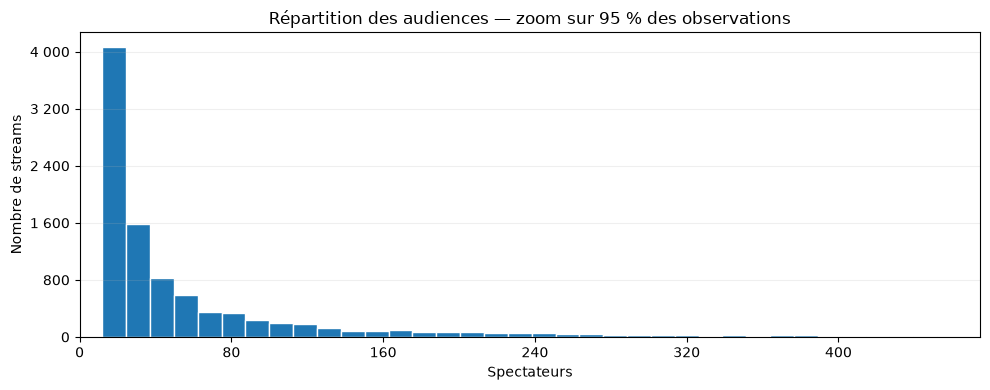

499 observations au-dessus de 452 spectateurs non affichées sur cette figure (conservées dans le CSV).


In [11]:
audiences = df['viewer_count'].dropna()
limite = zoom95(audiences)
visibles = audiences[audiences <= limite]

fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(visibles, bins=35, edgecolor='white')
ax.set(xlabel='Spectateurs', ylabel='Nombre de streams',
       title='Répartition des audiences — zoom sur 95 % des observations')
ax.set_xlim(left=0, right=max(limite * 1.05, 1))
axe_entier(ax, 'x'); axe_entier(ax, 'y')
ax.grid(axis='y', alpha=0.2)
plt.tight_layout(); plt.show()
print(f"{len(audiences) - len(visibles)} observations au-dessus de {nombre_fr(limite)} spectateurs non affichées sur cette figure (conservées dans le CSV).")

**Lecture :** cet histogramme montre les 95 % d’audiences les plus faibles pour rendre la distribution lisible. Les 5 % restants sont exclus uniquement du tracé et conservés dans le dataset.

### Figure 2 — Nuage de points : heure de début du live et audience

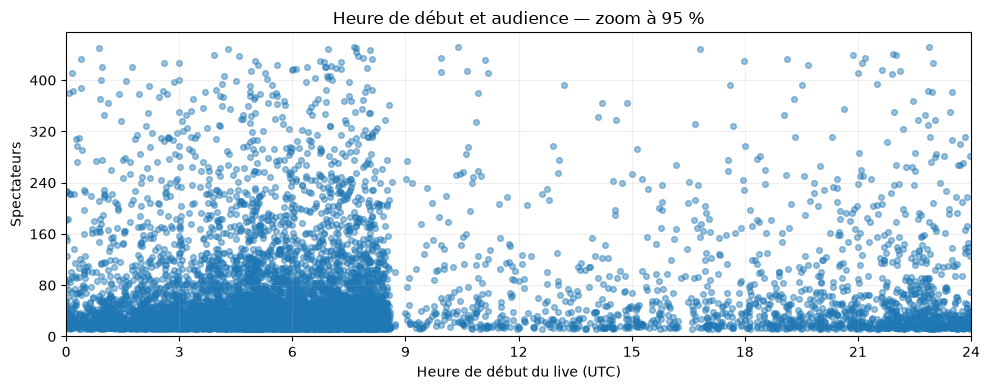

Les 5 % de plus grosses audiences ne figurent pas sur ce zoom, mais restent dans les analyses.


In [12]:
heures = df['started_at'].dt.hour + df['started_at'].dt.minute / 60
limite = zoom95(df['viewer_count'])

fig, ax = plt.subplots(figsize=(10, 4))
masque = df['viewer_count'].notna() & (df['viewer_count'] <= limite) & heures.notna()
ax.scatter(heures[masque], df.loc[masque, 'viewer_count'], alpha=0.45, s=17)
ax.set(xlabel='Heure de début du live (UTC)', ylabel='Spectateurs',
       title='Heure de début et audience — zoom à 95 %')
ax.set_xlim(0, 24)
ax.set_ylim(0, max(limite * 1.05, 1))
ax.set_xticks(range(0, 25, 3))
axe_entier(ax, 'y')
ax.grid(alpha=0.2)
plt.tight_layout(); plt.show()
print('Les 5 % de plus grosses audiences ne figurent pas sur ce zoom, mais restent dans les analyses.')

**Lecture :** la majorité des points devient visible grâce au zoom. Attention, les heures sont celles du **début des lives encore actifs** lors de la capture : ce graphique ne mesure pas les audiences à différentes heures de la journée.

### Figure 3 — Courbe : classement des 30 streams les plus regardés

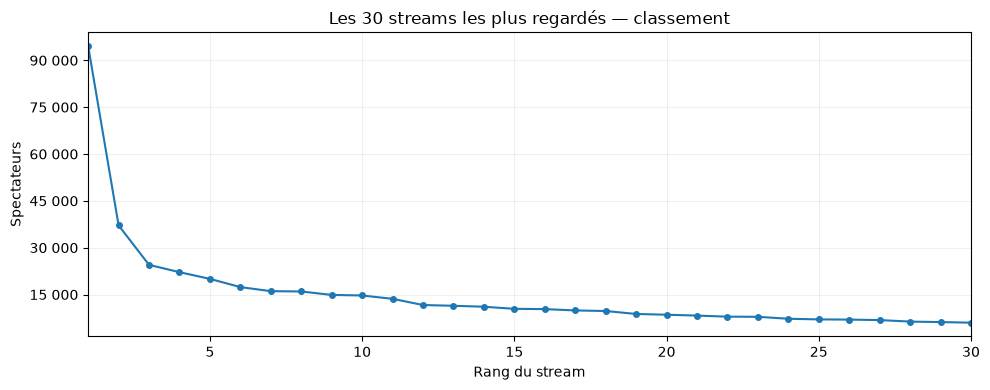

Maximum du top 30 : 94 540 spectateurs.


In [13]:
top30 = df.nlargest(30, 'viewer_count').reset_index(drop=True)
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(np.arange(1, len(top30)+1), top30['viewer_count'], marker='o', markersize=4)
ax.set(xlabel='Rang du stream', ylabel='Spectateurs',
       title='Les 30 streams les plus regardés — classement')
ax.set_xlim(1, max(30, len(top30)))
axe_entier(ax, 'y')
ax.grid(alpha=0.2)
plt.tight_layout(); plt.show()
print('Maximum du top 30 :', nombre_fr(top30['viewer_count'].max()), 'spectateurs.')

**Lecture :** l’écart entre les premières places peut être considérable. Il s’agit d’un classement lors d’une seule collecte, **pas** d’une évolution dans le temps.

### Figure 4 — Barres : 10 jeux / catégories les plus présents

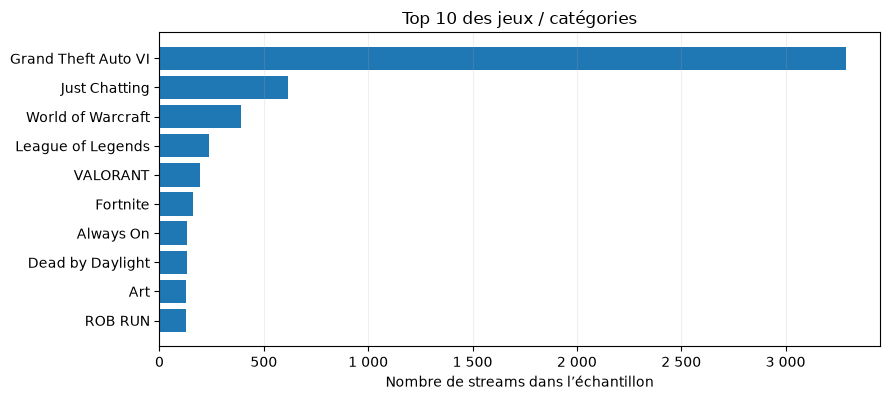

In [14]:
top_jeux = df['game_name'].fillna('Non renseigné').value_counts().head(10).sort_values()
fig, ax = plt.subplots(figsize=(9, 4.1))
ax.barh(top_jeux.index, top_jeux.values)
ax.set(xlabel='Nombre de streams dans l’échantillon', title='Top 10 des jeux / catégories')
ax.xaxis.set_major_formatter(fmt)
ax.grid(axis='x', alpha=.2)
plt.tight_layout(); plt.show()

**Lecture :** ce classement mesure le nombre de streams présents dans **cet échantillon des streams les plus regardés**, et non le nombre total de streams Twitch par jeu.

### Figure 5 — Barres d’erreur : médiane et dispersion (quartiles)

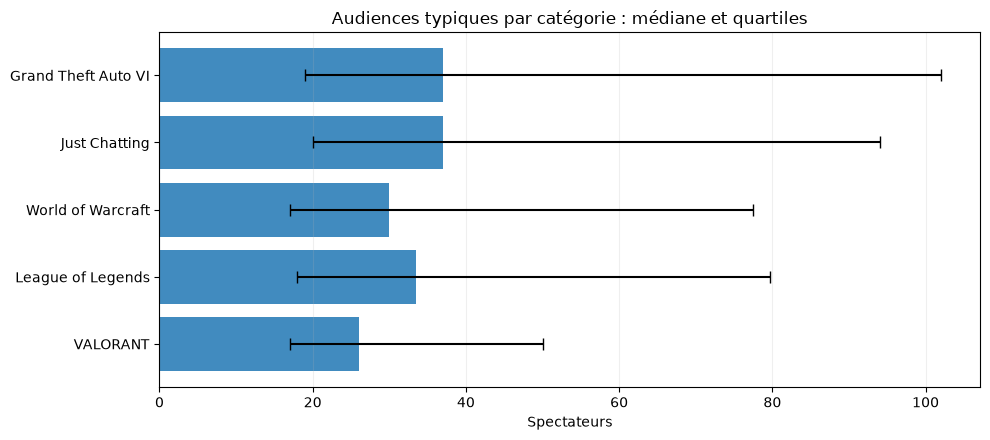

Barres : médiane ; traits : de Q1 (25 %) à Q3 (75 %).


In [15]:
# Médiane et intervalle interquartile : moins sensibles aux très gros streams
principaux = df['game_name'].fillna('Non renseigné').value_counts().head(5).index
stats = (df.assign(game_name=df['game_name'].fillna('Non renseigné'))
         .query('game_name in @principaux')
         .groupby('game_name')['viewer_count']
         .agg(mediane='median', q1=lambda x: x.quantile(0.25), q3=lambda x: x.quantile(0.75))
         .reindex(principaux))

yerr = np.vstack([
    (stats['mediane'] - stats['q1']).clip(lower=0).to_numpy(),
    (stats['q3'] - stats['mediane']).clip(lower=0).to_numpy()
])
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.barh(stats.index[::-1], stats['mediane'].iloc[::-1],
        xerr=yerr[:, ::-1], capsize=4, alpha=.85)
ax.set(xlabel='Spectateurs', title='Audiences typiques par catégorie : médiane et quartiles')
axe_entier(ax, 'x')
ax.grid(axis='x', alpha=0.2)
plt.tight_layout(); plt.show()
print('Barres : médiane ; traits : de Q1 (25 %) à Q3 (75 %).')

**Lecture :** la médiane représente mieux une audience typique lorsque quelques streams sont très populaires. Les traits indiquent la moitié centrale des audiences (du 1er au 3e quartile), et non un intervalle de confiance.

## 4. Nettoyage proposé

In [16]:
# Pour une seule capture, un ID de stream ne doit apparaître qu'une fois.
# Si des collectes successives sont ajoutées au même CSV : utiliser (id, collected_at).
cles = ['id', 'collected_at']
propre = df.drop_duplicates(subset=cles).copy()
propre = propre[propre['viewer_count'].notna() & (propre['viewer_count'] >= 0)]
propre = propre[propre['collected_at'].notna() & propre['started_at'].notna()]
propre = propre[propre['started_at'] <= propre['collected_at']]
propre['game_name'] = propre['game_name'].fillna('Non renseigné')
propre['title'] = propre['title'].fillna('Titre non renseigné')
propre['duree_live_minutes'] = (propre['collected_at'] - propre['started_at']).dt.total_seconds() / 60
print('Lignes avant :', len(df), '| après :', len(propre))
print('Durée médiane des lives en cours (min) :', round(propre['duree_live_minutes'].median(), 1))
display(propre.head(3))

Lignes avant : 10000 | après : 10000
Durée médiane des lives en cours (min) : 223.0


,id,user_id,user_name,game_id,game_name,title,viewer_count,started_at,language,collected_at,duree_live_minutes
0,317912867703,267160288,caseoh_,1867279146,Grand Theft Auto VI,🟨LOSING MY MIND🟨,94540,2026-11-18 19:36:58+00:00,en,2026-11-19 08:37:47.999548+00:00,780.833326
1,321144853726,220476955,IShowSpeed,1867279146,Grand Theft Auto VI,🔴PLAYING GTA 6 EARLY ACCESS GAMEPLAY GET IN HERE!,37134,2026-11-18 13:18:28+00:00,en,2026-11-19 08:37:47.999548+00:00,1159.333326
2,319272117607,45044816,MontanaBlack88,1867279146,Grand Theft Auto VI,GTA6 NACH 13 JAHREN WARTEN UNSICHER MACHEN | G...,24500,2026-11-19 07:42:23+00:00,de,2026-11-19 08:37:47.999548+00:00,55.416659


**Nettoyage :** vérifier doublons, dates et audiences négatives ; compléter uniquement les descriptions manquantes avec « Non renseigné ». Les audiences extrêmes plausibles sont conservées. Une répétition du même stream à **deux heures de collecte différentes** n’est pas un doublon.

## 5. Conclusion pour le projet fil rouge

| Question | Conclusion |
|---|---|
| **Quantité suffisante ?** | Oui pour une première fouille et un tableau de bord descriptif ; insuffisante seule pour prédire une évolution temporelle. |
| **Qualité des données ?** | Contrôler identifiants, dates, valeurs manquantes et audiences négatives. |
| **Lisibilité des figures ?** | Les audiences extrêmes créent des échelles écrasées ; certains graphiques zooment sur 95 % des observations **sans effacer les valeurs**. |
| **Biais à anticiper ?** | `Get Streams` remonte d’abord les streams les plus regardés : l’échantillon n’est pas aléatoire. |
| **Architecture proposée ?** | API Helix → collecte Python → PostgreSQL → Streamlit, avec historisation de la date de chaque capture. |
| **Pour le Machine Learning ?** | Collecter de nouvelles observations datées, sur plusieurs jours ou semaines, en suivant idéalement aussi des streamers fixes. |

**En résumé :** ce CSV est une photographie des streams actifs. Pour analyser l’évolution des audiences, il faudra conserver plusieurs collectes dans le temps.